# MNIST Digit Classification: ANN, SVM, and CNN

A comparative deep learning and machine learning project for recognizing handwritten digits (0–9) from the MNIST dataset.

## Project goals
- Prepare and visualize the MNIST dataset.
- Compare Artificial Neural Networks (ANNs) with different hidden-layer sizes.
- Compare SVM kernels on a manageable training subset.
- Build and tune a Convolutional Neural Network (CNN).
- Evaluate models using accuracy, classification reports, confusion matrices, and training time.

**Dataset:** MNIST is loaded directly through `tensorflow.keras.datasets`, so no manual dataset download or upload is required.

## 1. Imports and reproducibility

In [1]:
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.datasets import mnist
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Flatten, Conv2D, MaxPooling2D, Dropout
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Load and explore MNIST

MNIST is provided by Keras. The original training set contains 60,000 images and the test set contains 10,000 images. Each image is 28×28 grayscale pixels.

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)


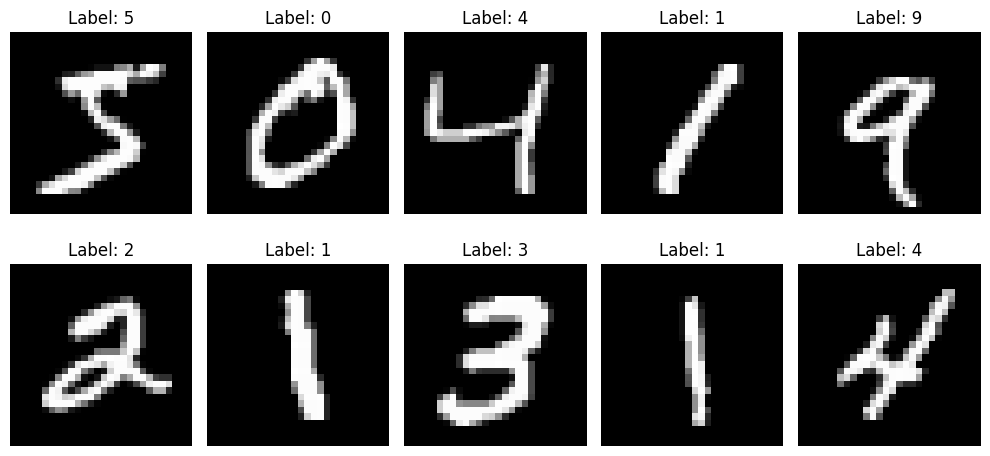

In [2]:
(x_train_full, y_train_full), (x_test, y_test) = mnist.load_data()

print("Training images:", x_train_full.shape)
print("Training labels:", y_train_full.shape)
print("Test images:", x_test.shape)
print("Test labels:", y_test.shape)

fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for ax, image, label in zip(axes.ravel(), x_train_full[:10], y_train_full[:10]):
    ax.imshow(image, cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Preprocessing and validation split

Pixel values are normalized exactly once to the range [0, 1]. A validation set is split from the original training data; the official test set is held out for final evaluation.

In [3]:
# ANN and SVM representation: flattened 784-dimensional vectors
X_train_flat = x_train_full.astype("float32").reshape(-1, 784) / 255.0
X_test_flat = x_test.astype("float32").reshape(-1, 784) / 255.0

X_train_ann, X_val_ann, y_train_ann, y_val_ann = train_test_split(
    X_train_flat, y_train_full,
    test_size=0.1, random_state=SEED, stratify=y_train_full
)

# CNN representation: 28 x 28 x 1
X_train_cnn = x_train_full.astype("float32")[..., np.newaxis] / 255.0
X_val_cnn = X_train_cnn[:0]  # replaced below using the same stratified indices
X_test_cnn = x_test.astype("float32")[..., np.newaxis] / 255.0

indices = np.arange(len(y_train_full))
train_idx, val_idx = train_test_split(
    indices, test_size=0.1, random_state=SEED, stratify=y_train_full
)
X_train_cnn, X_val_cnn = X_train_cnn[train_idx], X_train_cnn[val_idx]
y_train_cnn, y_val_cnn = y_train_full[train_idx], y_train_full[val_idx]

print("ANN train/validation:", X_train_ann.shape, X_val_ann.shape)
print("CNN train/validation:", X_train_cnn.shape, X_val_cnn.shape)

ANN train/validation: (54000, 784) (6000, 784)
CNN train/validation: (54000, 28, 28, 1) (6000, 28, 28, 1)


## 4. ANN experiments

Train simple fully connected networks with different numbers of neurons in the first hidden layer. The validation set is used to compare configurations.

In [4]:
ann_results = []
ann_models = {}

for neurons in [64, 128, 256]:
    model = Sequential([
        Input(shape=(784,)),
        Dense(neurons, activation="relu"),
        Dense(64, activation="relu"),
        Dense(10, activation="softmax")
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    start = time.time()
    history = model.fit(
        X_train_ann, y_train_ann,
        validation_data=(X_val_ann, y_val_ann),
        epochs=5, batch_size=32, verbose=0
    )
    elapsed = time.time() - start
    val_loss, val_accuracy = model.evaluate(X_val_ann, y_val_ann, verbose=0)

    ann_models[neurons] = (model, history)
    ann_results.append({
        "hidden_neurons": neurons,
        "validation_accuracy": val_accuracy,
        "training_time_sec": elapsed,
        "parameters": model.count_params()
    })

ann_results_df = pd.DataFrame(ann_results).sort_values(
    "validation_accuracy", ascending=False
)
display(ann_results_df)

,hidden_neurons,validation_accuracy,training_time_sec,parameters
2,256,0.975333,27.186692,218058
1,128,0.971667,28.869077,109386
0,64,0.969000,30.564468,55050


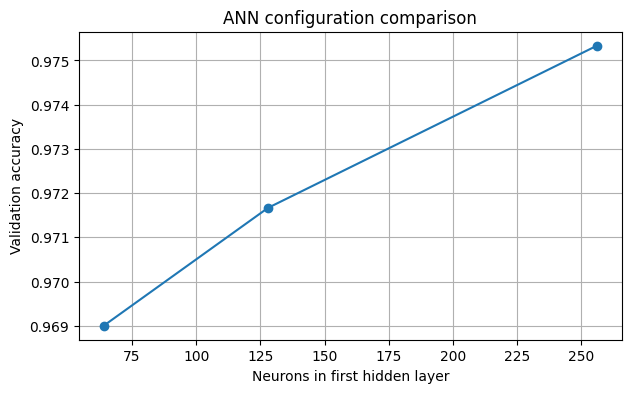

In [5]:
plt.figure(figsize=(7, 4))
plt.plot(
    ann_results_df["hidden_neurons"],
    ann_results_df["validation_accuracy"], marker="o"
)
plt.xlabel("Neurons in first hidden layer")
plt.ylabel("Validation accuracy")
plt.title("ANN configuration comparison")
plt.grid(True)
plt.show()

## 5. SVM kernel comparison

SVM training on all 60,000 images can be slow. To keep the experiment practical, this section uses a reproducible stratified subset of 10,000 training images. Features are standardized inside each pipeline to avoid data leakage.

In [6]:
X_svm_train, _, y_svm_train, _ = train_test_split(
    X_train_flat, y_train_full,
    train_size=10000, random_state=SEED, stratify=y_train_full
)

svm_results = []
svm_models = {}

for kernel in ["linear", "rbf", "poly"]:
    svm = make_pipeline(
        StandardScaler(),
        SVC(kernel=kernel, C=1.0, gamma="scale")
    )
    start = time.time()
    svm.fit(X_svm_train, y_svm_train)
    train_seconds = time.time() - start

    start = time.time()
    predictions = svm.predict(X_test_flat)
    test_seconds = time.time() - start

    accuracy = accuracy_score(y_test, predictions)
    svm_models[kernel] = svm
    svm_results.append({
        "kernel": kernel,
        "test_accuracy": accuracy,
        "training_time_sec": train_seconds,
        "prediction_time_sec": test_seconds
    })

svm_results_df = pd.DataFrame(svm_results).sort_values(
    "test_accuracy", ascending=False
)
display(svm_results_df)

,kernel,test_accuracy,training_time_sec,prediction_time_sec
1,rbf,0.9415,12.493609,30.368734
0,linear,0.9161,5.267456,8.001227
2,poly,0.9081,25.443417,24.661979


## 6. CNN model and training

A CNN preserves the two-dimensional structure of the images. The validation set—not the official test set—is used for early stopping and model selection.

In [7]:
def build_cnn():
    model = Sequential([
        Input(shape=(28, 28, 1)),
        Conv2D(32, kernel_size=3, activation="relu"),
        MaxPooling2D(pool_size=2),
        Conv2D(64, kernel_size=3, activation="relu"),
        MaxPooling2D(pool_size=2),
        Flatten(),
        Dense(128, activation="relu"),
        Dropout(0.25),
        Dense(10, activation="softmax")
    ])
    return model

cnn_model = build_cnn()
cnn_model.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
cnn_model.summary()

early_stopping = EarlyStopping(
    monitor="val_accuracy", patience=3, restore_best_weights=True
)

start = time.time()
cnn_history = cnn_model.fit(
    X_train_cnn, y_train_cnn,
    validation_data=(X_val_cnn, y_val_cnn),
    epochs=15, batch_size=64,
    callbacks=[early_stopping], verbose=1
)
cnn_training_time = time.time() - start

val_loss, val_accuracy = cnn_model.evaluate(X_val_cnn, y_val_cnn, verbose=0)
print(f"Best-restored CNN validation accuracy: {val_accuracy:.4f}")
print(f"Training time: {cnn_training_time:.2f} seconds")
print(f"Trainable parameters: {cnn_model.count_params():,}")

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 19s 15ms/step - accuracy: 0.8944 - loss: 0.3337 - val_accuracy: 0.9698 - val_loss: 0.1067
Epoch 2/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9721 - loss: 0.0908 - val_accuracy: 0.9747 - val_loss: 0.0876
Epoch 3/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9807 - loss: 0.0638 - val_accuracy: 0.9803 - val_loss: 0.0642
Epoch 4/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9839 - loss: 0.0526 - val_accuracy: 0.9823 - val_loss: 0.0569
Epoch 5/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9867 - loss: 0.0430 - val_accuracy: 0.9875 - val_loss: 0.0470
Epoch 6/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9884 - loss: 0.0381 - val_accuracy: 0.9860 - val_loss: 0.0480
Epoch 7/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9895 - loss: 0.0331 - val_accuracy: 0.9867 - val_loss: 0.0487
Epoch 8/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9912 - loss: 0.0288 - val_accuracy: 

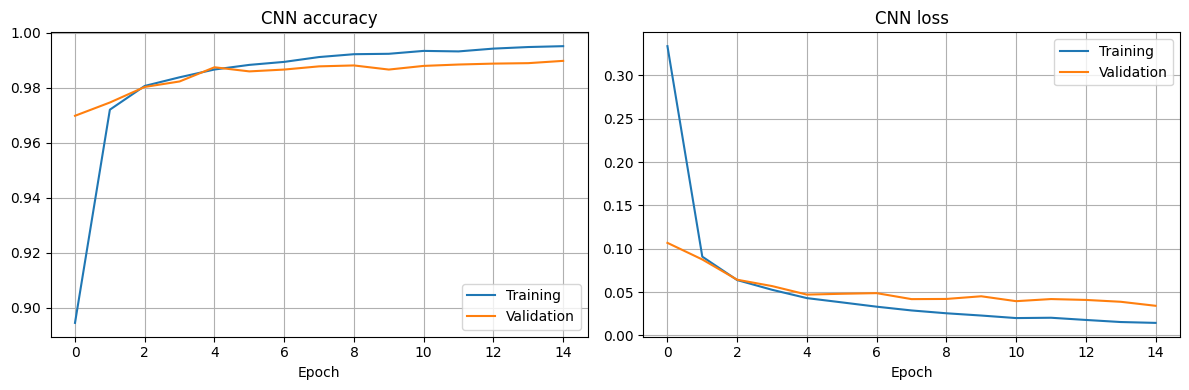

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(cnn_history.history["accuracy"], label="Training")
axes[0].plot(cnn_history.history["val_accuracy"], label="Validation")
axes[0].set_title("CNN accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(cnn_history.history["loss"], label="Training")
axes[1].plot(cnn_history.history["val_loss"], label="Validation")
axes[1].set_title("CNN loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True)
plt.tight_layout()
plt.show()

## 7. Final CNN test evaluation

The official test set is evaluated after training and validation-based model selection.

In [9]:
test_loss, test_accuracy = cnn_model.evaluate(X_test_cnn, y_test, verbose=0)
test_probabilities = cnn_model.predict(X_test_cnn, verbose=0)
test_predictions = np.argmax(test_probabilities, axis=1)

print(f"CNN test accuracy: {test_accuracy:.4f}")
print("\\nClassification report:")
print(classification_report(y_test, test_predictions, digits=4))

CNN test accuracy: 0.9925
\nClassification report:
              precision    recall  f1-score   support

           0     0.9919    0.9959    0.9939       980
           1     0.9974    0.9982    0.9978      1135
           2     0.9913    0.9942    0.9927      1032
           3     0.9940    0.9871    0.9906      1010
           4     0.9949    0.9908    0.9929       982
           5     0.9855    0.9910    0.9883       892
           6     0.9958    0.9885    0.9921       958
           7     0.9913    0.9951    0.9932      1028
           8     0.9908    0.9918    0.9913       974
           9     0.9911    0.9911    0.9911      1009

    accuracy                         0.9925     10000
   macro avg     0.9924    0.9924    0.9924     10000
weighted avg     0.9925    0.9925    0.9925     10000



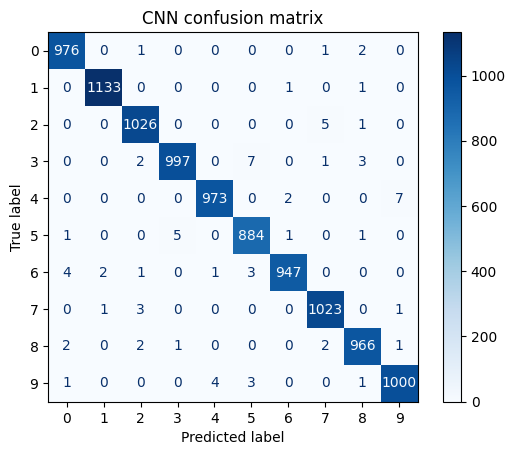

In [10]:
cm = confusion_matrix(y_test, test_predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues", values_format="d")
plt.title("CNN confusion matrix")
plt.show()

## 8. Compare model families

ANN and SVM scores below are from their stated evaluation setup; the CNN score is from the held-out MNIST test set. SVM uses 10,000 training samples. Training times depend on the machine and available hardware.

In [11]:
best_ann_row = ann_results_df.iloc[0]
best_svm_row = svm_results_df.iloc[0]

comparison = pd.DataFrame([
    {
        "model": f"ANN ({int(best_ann_row['hidden_neurons'])} first-layer neurons)",
        "evaluation_accuracy": best_ann_row["validation_accuracy"],
        "evaluation_split": "Validation"
    },
    {
        "model": f"SVM ({svm_results_df.iloc[0]['kernel']} kernel)",
        "evaluation_accuracy": best_svm_row["test_accuracy"],
        "evaluation_split": "Test; 10k training subset"
    },
    {
        "model": "CNN",
        "evaluation_accuracy": test_accuracy,
        "evaluation_split": "Test"
    }
])
display(comparison)

,model,evaluation_accuracy,evaluation_split
0,ANN (256 first-layer neurons),0.975333,Validation
1,SVM (rbf kernel),0.941500,Test; 10k training subset
2,CNN,0.992500,Test


## 9. Save the trained CNN

The model is saved locally as `mnist_cnn.keras`. This file is generated when the notebook is run and does not need to be committed to GitHub.

In [12]:
cnn_model.save("mnist_cnn.keras")
print("Saved model to mnist_cnn.keras")

Saved model to mnist_cnn.keras


## 10. Predict a few handwritten digits

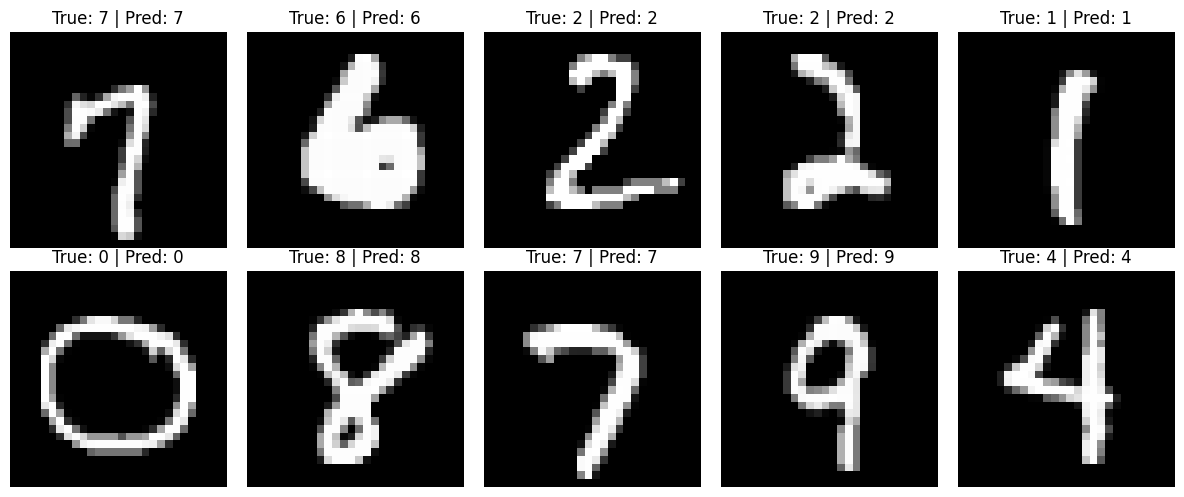

In [13]:
sample_indices = np.random.default_rng(SEED).choice(len(X_test_cnn), size=10, replace=False)
sample_images = X_test_cnn[sample_indices]
sample_predictions = np.argmax(cnn_model.predict(sample_images, verbose=0), axis=1)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, image, true_label, predicted_label in zip(
    axes.ravel(), sample_images, y_test[sample_indices], sample_predictions
):
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"True: {true_label} | Pred: {predicted_label}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Notes and limitations

- MNIST is downloaded automatically by Keras; there is no separate dataset folder to upload.
- The SVM comparison intentionally uses 10,000 training examples to reduce runtime.
- ANN configurations are compared using a validation split. SVM results are measured on the official test set for kernel comparison, while CNN training/model selection uses validation data and its final score is measured on the test set.
- Runtime and accuracy may vary slightly with TensorFlow, hardware, and random initialization.